# 3 · Decision tree

```{math}
G = 1 - \sum_k p_k^2
```

**Family:** tree models · **Task:** classification

The video draws yellow lines that chop the plane into boxes. Each line is a split
$x_j \le t$ chosen greedily to make the two children as pure as possible, measured by
Gini impurity $G$, where $p_k$ is the share of class $k$ in a node. For two classes
$G$ runs from 0 (pure) to 0.5 (a 50/50 mix). A split is scored by the
size-weighted impurity of its children:

```{math}
G_\text{split} = \frac{n_L}{n}G_L + \frac{n_R}{n}G_R .
```

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ml8 import data, models, scratch, plotting as P
P.use_style()
pd.set_option("display.precision", 4)

In [2]:
Xtr, ytr, Xte, yte = data.moons_arrays()
print(f"Gini of the whole training set: {scratch.gini(ytr):.3f}")
pd.DataFrame({"labels": ["[0 0 0 0]", "[0 0 1 1]", "[0 0 0 1]"],
              "G": [scratch.gini([0, 0, 0, 0]), scratch.gini([0, 0, 1, 1]), scratch.gini([0, 0, 0, 1])]})

Gini of the whole training set: 0.500


,labels,G
0,[0 0 0 0],0.000
1,[0 0 1 1],0.500
2,[0 0 0 1],0.375


## The first split, from scratch and from scikit-learn

`scratch.best_split` tries every midpoint between sorted values of every feature.

In [3]:
f, thr, g = scratch.best_split(Xtr, ytr)
sk = models.tree(1).fit(Xtr, ytr)
pd.DataFrame({"feature": [f"x{f + 1}", f"x{sk.tree_.feature[0] + 1}"],
              "threshold": [thr, sk.tree_.threshold[0]],
              "weighted child Gini": [g, (sk.tree_.weighted_n_node_samples[1:] * sk.tree_.impurity[1:]).sum() / len(ytr)]},
             index=["from scratch", "scikit-learn"])

,feature,threshold,weighted child Gini
from scratch,x2,0.2574,0.2793
scikit-learn,x2,0.2573,0.2793


## Growing the tree

The split lines (yellow) add up depth by depth, as in the video.

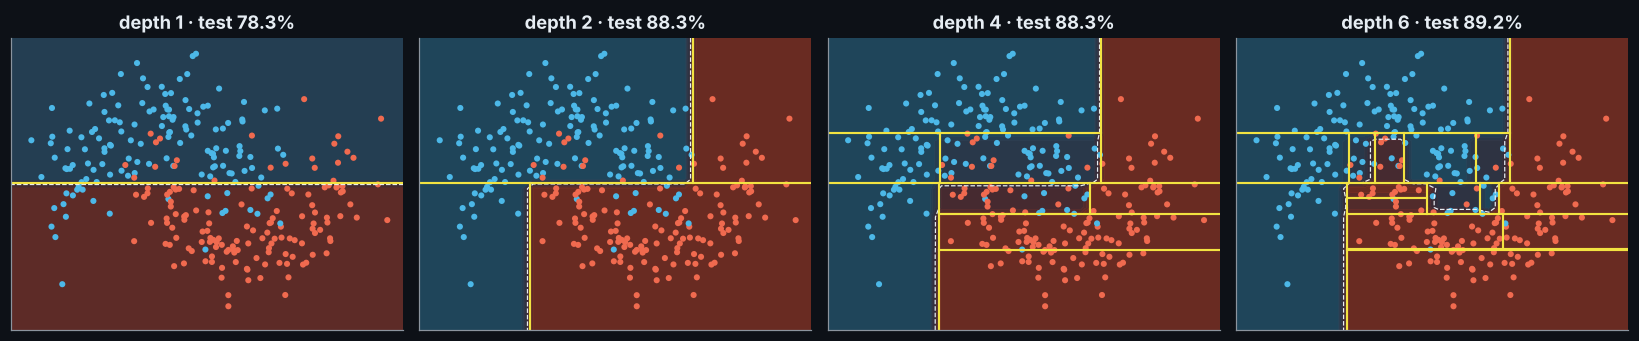

In [4]:
def split_segments(clf):
    t, segs = clf.tree_, []
    def walk(node, box):
        if t.children_left[node] == -1:
            return
        fe, th = t.feature[node], t.threshold[node]
        x0, x1, y0, y1 = box
        segs.append(((th, th), (y0, y1)) if fe == 0 else ((x0, x1), (th, th)))
        walk(t.children_left[node], (x0, th, y0, y1) if fe == 0 else (x0, x1, y0, th))
        walk(t.children_right[node], (th, x1, y0, y1) if fe == 0 else (x0, x1, th, y1))
    walk(0, (*data.X1_RANGE, *data.X2_RANGE))
    return segs

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, d in zip(axes, [1, 2, 4, 6]):
    clf = models.tree(d).fit(Xtr, ytr)
    P.plot_surface(ax, clf, Xtr, ytr, title=f"depth {d} · test {clf.score(Xte, yte):.1%}")
    for xs_, ys_ in split_segments(clf):
        ax.plot(xs_, ys_, c=P.YELLOW, lw=1.4)
plt.tight_layout()

max_depth,1,2,3,4,5,6,7,8,9,10,11,12
leaves,2.0000,4.0000,6.0000,9.0000,12.0000,17.0000,24.0000,29.0000,31.0000,32.0000,32.0000,32.0000
train,0.8321,0.9179,0.9179,0.9179,0.9429,0.9536,0.9750,0.9893,0.9964,1.0000,1.0000,1.0000
test,0.7833,0.8833,0.8833,0.8833,0.8917,0.8917,0.8833,0.8750,0.8750,0.8667,0.8667,0.8667


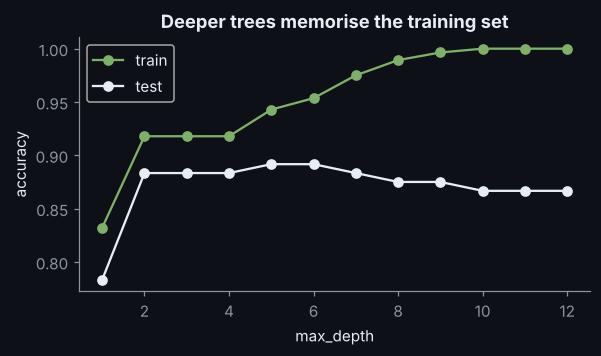

In [5]:
rows = []
for d in range(1, 13):
    clf = models.tree(d).fit(Xtr, ytr)
    rows.append({"max_depth": d, "leaves": clf.get_n_leaves(), "train": clf.score(Xtr, ytr), "test": clf.score(Xte, yte)})
depth = pd.DataFrame(rows).set_index("max_depth")
ax = depth[["train", "test"]].plot(marker="o", figsize=(6, 3), color=[P.GREEN, P.FG])
ax.set_ylabel("accuracy"); ax.set_title("Deeper trees memorise the training set");
depth.T

Training accuracy climbs toward 100% as the tree deepens, while test accuracy stalls:
a single deep tree overfits. The next two chapters fix this in two different ways,
by averaging many trees (random forest) or by adding small trees in sequence (boosting).

In [6]:
from sklearn.tree import export_text
print(export_text(models.tree(2).fit(Xtr, ytr), feature_names=["x1", "x2"]))

|--- x2 <= 0.26
|   |--- x1 <= -0.43
|   |   |--- class: 0
|   |--- x1 >  -0.43
|   |   |--- class: 1
|--- x2 >  0.26
|   |--- x1 <= 1.44
|   |   |--- class: 0
|   |--- x1 >  1.44
|   |   |--- class: 1

